# Examen Práctico 1
Primero ajustaremos una recta a diez datos y revisaremos sus errores. Después usaremos tres características del vino para estimar su concentración de flavonoides. Por último, calcularemos la probabilidad de que una flor sea virginica a partir de sus medidas.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from sklearn.datasets import load_wine, load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, roc_curve, roc_auc_score

pd.options.display.float_format = '{:.5g}'.format

## Parte 1. Regresión simple
### 1. Generar y describir los datos
Usamos una semilla fija para obtener los mismos diez valores cada vez. El error tiene media 0 y desviación estándar 0.5. Para describir la muestra calculamos la varianza con divisor $n-1$.

In [2]:
rng = np.random.default_rng(42)
x = np.arange(1, 11)
n = len(x)
y = 3 + 0.8 * x + rng.normal(0, 0.5, n)
datos = pd.DataFrame({'X': x, 'y': y})
display(datos)
display(datos.agg(['mean', 'var']).rename(index={'mean': 'Media', 'var': 'Varianza'}))
print(f'Correlación de Pearson: {datos.corr().loc["X", "y"]:.4f}')

,X,y
0,1,3.9524
1,2,4.08
2,3,5.7752
3,4,6.6703
4,5,6.0245
5,6,7.1489
6,7,8.6639
7,8,9.2419
8,9,10.192
9,10,10.573


,X,y
Media,5.5,7.2322
Varianza,9.1667,5.6232


Correlación de Pearson: 0.9813


### 2. Encontrar la recta por mínimos cuadrados
Restamos la media a cada valor. Con esas diferencias calculamos la pendiente y después el punto donde la recta cruza el eje vertical.

In [3]:
dx = x - x.mean()
dy = y - y.mean()
Sxx = sum(dx ** 2)
Sxy = sum(dx * dy)
b1 = Sxy / Sxx
b0 = y.mean() - b1 * x.mean()
print(f'Sxx = {Sxx:.4f}, Sxy = {Sxy:.4f}')
print(f'Modelo estimado: ŷ = {b0:.4f} + {b1:.4f} X')
print(f'Por cada unidad adicional de X, la estimación de y aumenta {b1:.4f} unidades.')

Sxx = 82.5000, Sxy = 63.4049
Modelo estimado: ŷ = 3.0052 + 0.7685 X
Por cada unidad adicional de X, la estimación de y aumenta 0.7685 unidades.


### 3. Comprobar la recta con matrices
La primera columna de la matriz contiene unos para estimar el intercepto. La segunda contiene los valores de X.

In [4]:
X = np.column_stack([np.ones(n), x])
producto = X.T @ X
inversa = np.linalg.inv(producto)
beta = inversa @ X.T @ y
print('XᵀX:', producto, sep='\n')
print('Inversa:', inversa, sep='\n')
print('Intercepto y pendiente:', beta)
print('¿Coinciden con el paso 2?', np.allclose(beta, [b0, b1]))

XᵀX:
[[ 10.  55.]
 [ 55. 385.]]
Inversa:
[[ 0.46666667 -0.06666667]
 [-0.06666667  0.01212121]]
Intercepto y pendiente: [3.00522026 0.76854438]
¿Coinciden con el paso 2? True


### 4. Separar la variación y construir la tabla ANOVA
El residuo es el valor observado menos el estimado. Dividimos la variación total (SST) en la parte que explica la recta (SSR) y la que queda en los residuos (SSE).

In [5]:
ajuste = X @ beta
residuo = y - ajuste
display(datos.assign(Estimado=ajuste, Residuo=residuo))
sst = sum((y - y.mean()) ** 2)
ssr = sum((ajuste - y.mean()) ** 2)
sse = sum(residuo ** 2)
msr = ssr / 1
mse = sse / (n - 2)
F = msr / mse

# La misma tabla servirá para la regresión con varios predictores.
def tabla_anova(ssr, sse, sst, gl_modelo, gl_error):
    msr = ssr / gl_modelo
    mse = sse / gl_error
    return pd.DataFrame({
        'Suma de cuadrados': [ssr, sse, sst],
        'Grados de libertad': [gl_modelo, gl_error, gl_modelo + gl_error],
        'Cuadrado medio': [msr, mse, np.nan],
        'F': [msr / mse, np.nan, np.nan]
    }, index=['Regresión', 'Error', 'Total']).fillna('')

display(tabla_anova(ssr, sse, sst, 1, n - 2))
print('¿SST = SSR + SSE?', np.isclose(sst, ssr + sse))
print(f'R² = {ssr/sst:.4f}. La recta explica {100*ssr/sst:.1f}% de la variación de y.')

,X,y,Estimado,Residuo
0,1,3.9524,3.7738,0.17859
1,2,4.08,4.5423,-0.4623
2,3,5.7752,5.3109,0.46437
3,4,6.6703,6.0794,0.59088
4,5,6.0245,6.8479,-0.82346
5,6,7.1489,7.6165,-0.46758
6,7,8.6639,8.385,0.27889
7,8,9.2419,9.1536,0.088303
8,9,10.192,9.9221,0.26948
9,10,10.573,10.691,-0.11719


,Suma de cuadrados,Grados de libertad,Cuadrado medio,F
Regresión,48.729,1,48.729,207.46
Error,1.879,8,0.23488,
Total,50.609,9,,


¿SST = SSR + SSE? True
R² = 0.9629. La recta explica 96.3% de la variación de y.


### 5. Medir la incertidumbre de los coeficientes
Calculamos el error estándar de cada coeficiente. Para su intervalo de confianza usamos el valor crítico de t con 8 grados de libertad. En cada prueba bilateral, la hipótesis inicial es que el coeficiente vale cero.

In [6]:
se_pendiente = np.sqrt(mse / Sxx)
se_intercepto = np.sqrt(mse * (1/n + x.mean()**2 / Sxx))
se = np.array([se_intercepto, se_pendiente])
critico = stats.t.ppf(0.975, n - 2)
t = beta / se
valor_p = 2 * stats.t.sf(abs(t), n - 2)
pd.DataFrame({'Estimación': beta, 'Error estándar': se, 'IC 95% inferior': beta - critico*se,
              'IC 95% superior': beta + critico*se, 't': t, 'Valor p': valor_p,
              'Rechazar hipótesis al 5%': valor_p < 0.05}, index=['Intercepto', 'Pendiente'])

,Estimación,Error estándar,IC 95% inferior,IC 95% superior,t,Valor p,Rechazar hipótesis al 5%
Intercepto,3.0052,0.33108,2.2418,3.7687,9.0771,1.7403e-05,True
Pendiente,0.76854,0.053358,0.6455,0.89159,14.404,5.2755e-07,True


En esta muestra, el intervalo del 95% para el intercepto va de 2.24 a 3.77 e incluye el valor usado para generar los datos, β₀ = 3. El intervalo para la pendiente va de 0.646 a 0.892 y también incluye su valor verdadero, β₁ = 0.8.

### 6. Revisar los residuos y la influencia
Con un solo predictor, la prueba F del modelo y la prueba t de la pendiente evalúan la misma hipótesis. La distancia de Cook mide cuánto puede cambiar el ajuste al quitar un punto. En su fórmula contamos los dos coeficientes, incluido el intercepto.

F = 207.4648, t² = 207.4648. ¿Coinciden? True


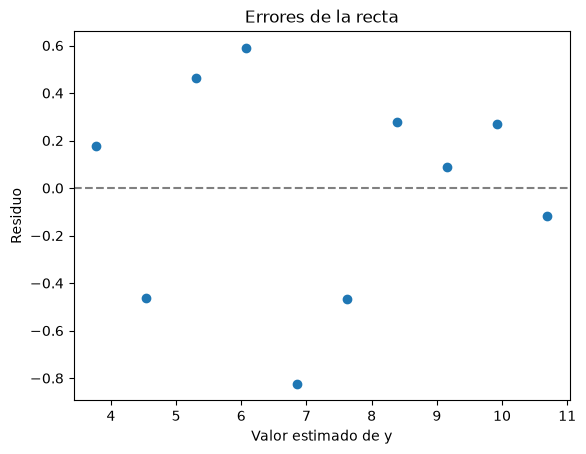

In [7]:
print(f'F = {F:.4f}, t² = {t[1]**2:.4f}. ¿Coinciden? {np.isclose(F, t[1]**2)}')
plt.scatter(ajuste, residuo)
plt.axhline(0, color='gray', linestyle='--')
plt.xlabel('Valor estimado de y')
plt.ylabel('Residuo')
plt.title('Errores de la recta')
plt.show()

Los residuos quedan a ambos lados de cero, entre −0.82 y 0.59. No se aprecia una curva ni una forma de embudo. La gráfica es compatible con una recta y una varianza aproximadamente constante, aunque diez puntos dan poca información para detectar un patrón.

In [8]:
h = np.diag(X @ inversa @ X.T)
cook = residuo**2 / (2*mse) * h / (1-h)**2
display(datos.assign(Apalancamiento=h, Cook=cook))
print(f'El punto con mayor influencia tiene X = {x[cook.argmax()]} y Cook = {cook.max():.3f}.')

,X,y,Apalancamiento,Cook
0,1,3.9524,0.34545,0.054748
1,2,4.08,0.24848,0.20017
2,3,5.7752,0.17576,0.11876
3,4,6.6703,0.12727,0.1242
4,5,6.0245,0.10303,0.18485
5,6,7.1489,0.10303,0.059599
6,7,8.6639,0.12727,0.027667
7,8,9.2419,0.17576,0.0042942
8,9,10.192,0.24848,0.068014
9,10,10.573,0.34545,0.023571


El punto con mayor influencia tiene X = 2 y Cook = 0.200.


La mayor distancia de Cook es 0.200, en X = 2. Queda por debajo de 1 y también del criterio más estricto, 4/n = 0.4. Ninguna observación se identifica como influyente con estas reglas.

## Parte 2. Regresión múltiple con vinos
### 1. Explorar las relaciones
Comparamos los tres predictores con la concentración de flavonoides. Cada punto de las gráficas representa un vino.

,Fenoles totales,Razón óptica OD280/OD315,Prolina,Flavonoides
Fenoles totales,1,0.69995,0.49811,0.86456
Razón óptica OD280/OD315,0.69995,1,0.31276,0.78719
Prolina,0.49811,0.31276,1,0.49419
Flavonoides,0.86456,0.78719,0.49419,1


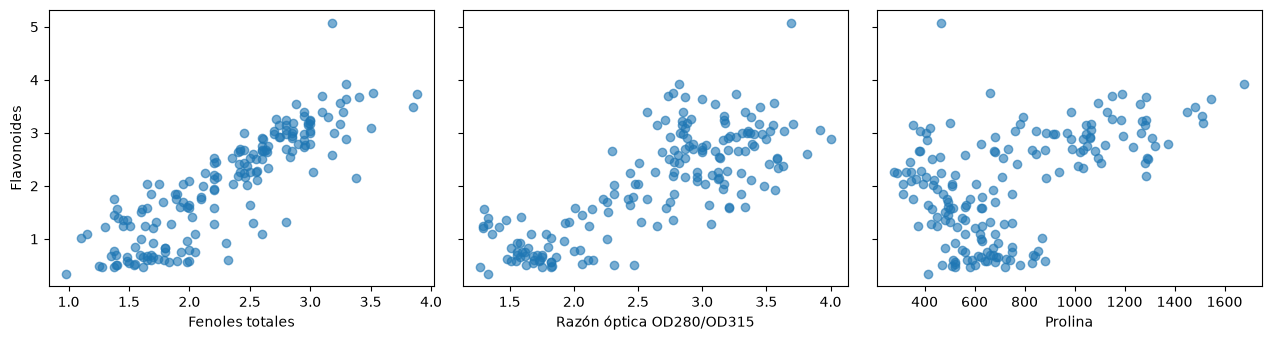

In [9]:
vino = load_wine(as_frame=True).data.rename(columns={
    'total_phenols': 'Fenoles totales',
    'od280/od315_of_diluted_wines': 'Razón óptica OD280/OD315',
    'proline': 'Prolina',
    'flavanoids': 'Flavonoides'
})
predictores = ['Fenoles totales', 'Razón óptica OD280/OD315', 'Prolina']
respuesta = 'Flavonoides'
correlaciones = vino[predictores + [respuesta]].corr()
display(correlaciones)
fig, ejes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for eje, nombre in zip(ejes, predictores):
    eje.scatter(vino[nombre], vino[respuesta], alpha=0.6)
    eje.set_xlabel(nombre)
ejes[0].set_ylabel('Flavonoides')
plt.tight_layout()
plt.show()

El par de predictores con mayor correlación es **fenoles totales y razón óptica OD280/OD315**. Los vinos con más fenoles totales tienden a tener un valor mayor de esa medida óptica.

### 2. Calcular los coeficientes y sus errores estándar
Agregamos una columna de unos. Ahora estimamos cuatro coeficientes. Cada pendiente representa el cambio esperado en flavonoides al aumentar ese predictor una unidad y mantener fijos los otros dos.

In [10]:
y_vino = vino[respuesta].to_numpy()
n_vino = len(vino)
X_vino = np.column_stack([np.ones(n_vino), vino[predictores]])
k_beta = X_vino.shape[1]
inv_vino = np.linalg.inv(X_vino.T @ X_vino)
beta_vino = inv_vino @ X_vino.T @ y_vino
estimado = X_vino @ beta_vino
error = y_vino - estimado
sse_vino = sum(error**2)
gl_error = n_vino - k_beta
mse_vino = sse_vino / gl_error
se_vino = np.sqrt(mse_vino * np.diag(inv_vino))
print('Dimensiones de la matriz:', X_vino.shape)
pd.DataFrame({'Coeficiente': beta_vino, 'Error estándar': se_vino},
             index=['Intercepto'] + predictores)

Dimensiones de la matriz: (178, 4)


,Coeficiente,Error estándar
Intercepto,-1.5974,0.13387
Fenoles totales,0.89213,0.078816
Razón óptica OD280/OD315,0.51219,0.063425
Prolina,0.00032319,0.00011778


### 3. Evaluar el modelo completo
La prueba F global pregunta si las tres pendientes podrían ser cero al mismo tiempo. El R² ajustado toma en cuenta cuántos predictores usamos.

In [11]:
p = len(predictores)
sst_vino = sum((y_vino - y_vino.mean())**2)
ssr_vino = sum((estimado - y_vino.mean())**2)
F_vino = (ssr_vino / p) / mse_vino
p_global = stats.f.sf(F_vino, p, gl_error)
r2 = 1 - sse_vino / sst_vino
r2_aj = 1 - (1-r2) * (n_vino-1) / gl_error
display(tabla_anova(ssr_vino, sse_vino, sst_vino, p, gl_error))
print(f'F = {F_vino:.3f}, valor p = {p_global:.3g}, R² = {r2:.4f}, R² ajustado = {r2_aj:.4f}')

,Suma de cuadrados,Grados de libertad,Cuadrado medio,F
Regresión,144.85,3,48.283,264.62
Error,31.748,174,0.18246,
Total,176.6,177,,


F = 264.617, valor p = 1.39e-64, R² = 0.8202, R² ajustado = 0.8171


El valor p es menor que 0.05. Hay evidencia de que al menos uno de los predictores se relaciona con la concentración de flavonoides.

### 4. Revisar si los predictores repiten información
Para cada predictor, intentamos explicarlo usando los otros dos. Si estos lo explican casi por completo, el R² auxiliar se acerca a 1 y el factor de inflación de la varianza (VIF) crece.

In [12]:
vifs = {}
for nombre in predictores:
    otros = vino[predictores].drop(columns=nombre)
    auxiliar = sm.OLS(vino[nombre], sm.add_constant(otros)).fit()
    vifs[nombre] = 1 / (1 - auxiliar.rsquared)

vif = pd.Series(vifs, name='VIF')
display(vif.to_frame())
print('Mayor VIF:', vif.idxmax())

,VIF
Fenoles totales,2.3603
Razón óptica OD280/OD315,1.9671
Prolina,1.3345


Mayor VIF: Fenoles totales


Ningún predictor supera el límite de 10. Aunque los predictores comparten información, sus VIF quedan por debajo del nivel que el ejercicio considera grave.

### 5. Identificar vinos con valores poco comunes o influyentes
El apalancamiento mide qué tan inusual es la combinación de predictores de un vino. Para marcar los valores altos usamos el doble del apalancamiento promedio, que es $2(4)/178$ porque estimamos cuatro coeficientes, incluido el intercepto. También mostramos el resultado con los tres predictores para comparar las dos formas de contar. La distancia de Cook combina el apalancamiento con el tamaño del residuo.

In [13]:
H = X_vino @ inv_vino @ X_vino.T
h_vino = np.diag(H)
cook_vino = error**2 / (k_beta * mse_vino) * h_vino / (1-h_vino)**2
diagnostico = pd.DataFrame({'Apalancamiento': h_vino, 'Cook': cook_vino}, index=vino.index)
for cantidad in [p, k_beta]:
    limite = 2 * cantidad / n_vino
    marcados = diagnostico.index[h_vino > limite]
    print(f'Con {cantidad} términos: límite = {limite:.4f}, vinos marcados = {len(marcados)}')
    print('Índices:', marcados.tolist())

mayor_cook = diagnostico['Cook'].idxmax()
print(f'Mayor Cook: vino {mayor_cook}, D = {cook_vino.max():.3f}.')
print(f'Flavonoides de ese vino: {vino.loc[mayor_cook, respuesta]:.2f}')
print('Vinos con Cook > 1:', (cook_vino > 1).sum())

Con 3 términos: límite = 0.0337, vinos marcados = 25
Índices: [3, 5, 6, 7, 10, 14, 18, 22, 31, 51, 52, 58, 63, 70, 94, 98, 105, 106, 110, 121, 124, 152, 158, 159, 160]
Con 4 términos: límite = 0.0449, vinos marcados = 8
Índices: [3, 14, 18, 52, 63, 98, 105, 152]
Mayor Cook: vino 121, D = 0.184.
Flavonoides de ese vino: 5.08
Vinos con Cook > 1: 0


Al incluir el intercepto quedan 8 vinos con apalancamiento alto. Con tres predictores el límite baja y se marcan 25. El vino 121 destaca en las tres gráficas porque tiene 5.08 de flavonoides. Su distancia de Cook (0.184) es la mayor de la muestra, pero queda por debajo de 1. Según ese criterio, ningún vino tiene una influencia importante sobre el ajuste.

### 6. Comparar el modelo completo con uno reducido
Quitamos el predictor con mayor VIF y volvemos a ajustar el modelo con los mismos vinos. Preferimos un R² ajustado mayor y valores menores de AIC y BIC. Para estos dos criterios usamos la log-verosimilitud normal y contamos en $k$ los coeficientes y la varianza del error.

In [14]:
restantes = [nombre for nombre in predictores if nombre != vif.idxmax()]
completo = sm.OLS(y_vino, sm.add_constant(vino[predictores])).fit()
reducido = sm.OLS(y_vino, sm.add_constant(vino[restantes])).fit()
comparacion = {}
for etiqueta, modelo in [('Completo', completo), ('Reducido', reducido)]:
    k = len(modelo.params) + 1
    aic = -2 * modelo.llf + 2*k
    bic = -2 * modelo.llf + k*np.log(n_vino)
    comparacion[etiqueta] = [modelo.rsquared_adj, aic, bic]

pd.DataFrame.from_dict(comparacion, orient='index', columns=['R² ajustado', 'AIC', 'BIC'])

,R² ajustado,AIC,BIC
Completo,0.81712,208.28,224.19
Reducido,0.68427,304.5,317.22


Los tres criterios favorecen al modelo completo. Al quitar el predictor con mayor VIF perdemos información sobre los flavonoides, aun cuando parte de esa información también aparece en los otros predictores.

### 7. ¿Qué indican el VIF y un cambio de signo?
El R² del modelo mide cuánta variación en los flavonoides explican juntos los predictores. El VIF indica qué tan difícil es distinguir el aporte de un predictor cuando los demás se parecen a él. Por eso un modelo puede tener un R² alto y, al mismo tiempo, pendientes poco precisas.

Si una pendiente cambia de signo al quitar una variable, también cambió la comparación. Antes se mantenía fija esa variable. Al quitarla, el coeficiente puede recoger parte de la relación que ambas compartían con la respuesta. El cambio de signo por sí solo no demuestra una causa.

In [15]:
coeficientes = pd.DataFrame({'Completo': completo.params, 'Reducido': reducido.params})
coeficientes.rename(index={'const': 'Intercepto'}).fillna('Variable retirada')

,Completo,Reducido
Fenoles totales,0.89213,Variable retirada
Prolina,0.00032319,0.00087189
Razón óptica OD280/OD315,0.51219,0.98652
Intercepto,-1.5974,-1.1984


Las dos pendientes que podemos comparar conservan su signo positivo. Al retirar los fenoles totales, la pendiente de la razón óptica pasa de 0.51 a 0.99 y la de la prolina pasa de 0.00032 a 0.00087. Ambas aumentan porque el modelo reducido recoge con esas dos medidas parte de la relación que compartían con los fenoles.

## Parte 3 (extra). Clasificación de flores con regresión logística
### 1. Preparar los datos
Usamos 0 para versicolor y 1 para virginica. Conservamos la misma proporción de especies en entrenamiento y prueba. Para estandarizar, restamos la media y dividimos entre la desviación estándar de entrenamiento. Así las flores de prueba quedan fuera de la preparación del modelo.

In [16]:
iris = load_iris(as_frame=True)
seleccion = iris.target.isin([1, 2])
flores = iris.data.loc[seleccion].copy()
flores.columns = ['Largo del sépalo', 'Ancho del sépalo', 'Largo del pétalo', 'Ancho del pétalo']
especie = iris.target.loc[seleccion] - 1
x_ent, x_pru, y_ent, y_pru = train_test_split(
    flores, especie, test_size=0.20, stratify=especie, random_state=42)
escala = StandardScaler().fit(x_ent)
def estandarizar(datos):
    return pd.DataFrame(escala.transform(datos), columns=datos.columns, index=datos.index)

ent = sm.add_constant(estandarizar(x_ent))
pru = sm.add_constant(estandarizar(x_pru))
pd.DataFrame({'Total': especie.value_counts(), 'Entrenamiento': y_ent.value_counts(),
              'Prueba': y_pru.value_counts()}).rename(index={0: 'Versicolor', 1: 'Virginica'}).rename_axis(None)

,Total,Entrenamiento,Prueba
Versicolor,50,40,10
Virginica,50,40,10


### 2. Ajustar la regresión logística
El modelo estima la probabilidad de que una flor sea virginica. Para obtener la razón de momios (OR), elevamos $e$ al coeficiente. Hacemos lo mismo con los límites del intervalo de confianza del coeficiente.

In [17]:
logistico = sm.Logit(y_ent, ent).fit(disp=False)
ic = np.exp(logistico.conf_int())
resumen = pd.DataFrame({'Coeficiente': logistico.params, 'Error estándar': logistico.bse,
                        'z': logistico.tvalues, 'Valor p': logistico.pvalues,
                        'OR': np.exp(logistico.params), 'IC 95% inferior del OR': ic[0],
                        'IC 95% superior del OR': ic[1]})
resumen.rename(index={'const': 'Intercepto'})

,Coeficiente,Error estándar,z,Valor p,OR,IC 95% inferior del OR,IC 95% superior del OR
Intercepto,0.44768,0.9483,0.47209,0.63687,1.5647,0.24391,10.037
Largo del sépalo,-1.1384,2.2439,-0.50733,0.61192,0.32033,0.0039406,26.039
Ancho del sépalo,-0.81735,2.0913,-0.39084,0.69591,0.4416,0.0073274,26.614
Largo del pétalo,5.5039,4.0819,1.3484,0.17754,245.65,0.082377,7.3255e+05
Ancho del pétalo,6.5176,3.2553,2.0022,0.045266,676.98,1.1473,3.9947e+05


### 3. Interpretar las dos medidas con mayor coeficiente absoluto
Los momios se calculan dividiendo la probabilidad de virginica entre la de versicolor. Como estandarizamos las medidas, un aumento de una unidad equivale a una desviación estándar de entrenamiento.

In [18]:
principales = logistico.params.drop('const').abs().nlargest(2).index
for nombre in principales:
    print(f'{nombre}: al aumentar una desviación estándar, los momios de virginica')
    print(f'se multiplican por {resumen.loc[nombre, "OR"]:.1f}, manteniendo fijas las otras medidas.')

Ancho del pétalo: al aumentar una desviación estándar, los momios de virginica
se multiplican por 677.0, manteniendo fijas las otras medidas.
Largo del pétalo: al aumentar una desviación estándar, los momios de virginica
se multiplican por 245.7, manteniendo fijas las otras medidas.


Los intervalos de la tabla son amplios. Hay bastante incertidumbre sobre el tamaño exacto de esos cambios.

### 4. Evaluar las predicciones en prueba
Clasificamos como virginica cuando la probabilidad es al menos 0.5. La sensibilidad indica qué proporción de virginicas detectamos y la especificidad indica qué proporción de versicolor reconocemos.

,Predicha versicolor,Predicha virginica
Real versicolor,9,1
Real virginica,0,10


Exactitud = 95.0%, sensibilidad = 100.0%, especificidad = 90.0%


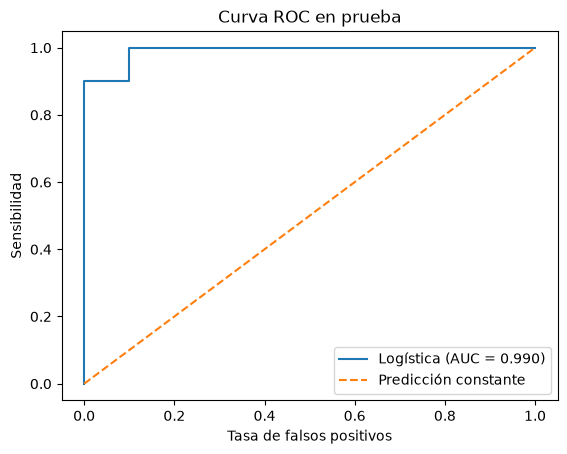

In [19]:
prob = logistico.predict(pru)
pred = (prob >= 0.5).astype(int)
matriz = confusion_matrix(y_pru, pred, labels=[0, 1])
display(pd.DataFrame(matriz, index=['Real versicolor', 'Real virginica'],
                     columns=['Predicha versicolor', 'Predicha virginica']))
vn, fp, fn, vp = matriz.ravel()
exactitud = accuracy_score(y_pru, pred)
auc = roc_auc_score(y_pru, prob)
print(f'Exactitud = {exactitud:.1%}, sensibilidad = {vp/(vp+fn):.1%}, especificidad = {vn/(vn+fp):.1%}')
fpr, tpr, umbrales = roc_curve(y_pru, prob)
plt.plot(fpr, tpr, label=f'Logística (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], '--', label='Predicción constante')
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Sensibilidad')
plt.title('Curva ROC en prueba')
plt.legend()
plt.show()

### 5. Comparar con una predicción constante
Las clases empatan en entrenamiento. Para desempatar elegimos versicolor, la primera moda. Todas las flores reciben el mismo puntaje de referencia.

In [20]:
clase_base = y_ent.mode().iloc[0]
base = np.full(len(y_pru), clase_base)
exactitud_base = accuracy_score(y_pru, base)
auc_base = roc_auc_score(y_pru, base)
display(pd.DataFrame({'Exactitud': [exactitud, exactitud_base], 'AUC': [auc, auc_base]},
                     index=['Logística', 'Clase constante']))
print(f'Mejora en exactitud: {100*(exactitud-exactitud_base):.1f} puntos porcentuales.')
print(f'Mejora en AUC: {auc-auc_base:.3f}.')

,Exactitud,AUC
Logística,0.95,0.99
Clase constante,0.5,0.5


Mejora en exactitud: 45.0 puntos porcentuales.
Mejora en AUC: 0.490.


In [21]:
correlacion_petalo = x_ent['Largo del pétalo'].corr(x_ent['Ancho del pétalo'])
print(f'Correlación en entrenamiento: {correlacion_petalo:.3f}')
print(f'Prueba global: LR = {logistico.llr:.2f}, valor p = {logistico.llr_pvalue:.2g}')
largo_petalo = iris.data['petal length (cm)']
print('Mayor largo en setosa (cm):', largo_petalo[iris.target == 0].max())
print('Menor largo en las otras especies (cm):', largo_petalo[iris.target != 0].min())

Correlación en entrenamiento: 0.837
Prueba global: LR = 102.38, valor p = 3.1e-21
Mayor largo en setosa (cm): 1.9
Menor largo en las otras especies (cm): 3.0


### 6. Interpretar los resultados
Con un nivel de 5%, solo el **ancho del pétalo** tiene un valor p menor que 0.05 al considerar las cuatro medidas juntas. El largo del pétalo también tiene un coeficiente grande, pero su intervalo del OR incluye 1.

En entrenamiento, el largo y el ancho del pétalo tienen una correlación de 0.84. Como suelen crecer juntos, cuesta estimar por separado cuánto aporta cada medida. Esto puede contribuir a que sus intervalos sean amplios. El resultado del largo del pétalo deja incertidumbre sobre su aporte individual.

La prueba de razón de verosimilitud compara el modelo de cuatro medidas con uno que solo tiene intercepto. El valor p de la prueba global es mucho menor que 0.05. En conjunto, las medidas ayudan a distinguir las dos especies.

El modelo distingue bien las dos especies en este conjunto de prueba y supera al clasificador constante. Solo evaluamos 20 flores, así que un error más o menos cambia la exactitud en cinco puntos porcentuales.

La prueba de Hosmer–Lemeshow compara las probabilidades estimadas con las frecuencias observadas en grupos. Su resultado depende del tamaño de la muestra y de cómo se formen los grupos. Con pocos datos puede pasar por alto diferencias importantes. Por sí sola tampoco indica si el modelo ordena bien las flores por probabilidad.

Si comparáramos setosa contra el resto, habría 50 setosa y 100 de las otras especies. Predecir siempre «resto» acertaría dos de cada tres veces, aunque perdería todas las setosa. El AUC examina qué tan bien se ordenan los ejemplos de ambas clases a través de distintos umbrales. Un puntaje constante daría un AUC de 0.5, lo que deja clara su falta de capacidad para distinguirlas.

En estos datos también hay **separación completa** para setosa contra el resto. El pétalo más largo de setosa mide 1.9 cm y el más corto de las otras especies mide 3.0 cm. Un corte en 2.5 cm las clasificaría todas correctamente. En una regresión logística sin penalización, la pendiente puede crecer en magnitud sin límite mientras mejora el ajuste. Por eso no existe una estimación finita de máxima verosimilitud para esa comparación.